# 04 · Method research, P2: decision

Findings behind this step ([`reports/data_analysis.md`](../reports/data_analysis.md)): fraud rate is not loss (B), loss is concentrated in large transactions (B), and the best-ranking model has the worst log loss (M2). So the decision must be priced in dollars, include the amount, and use calibrated probabilities.

Scores: the reference model (LightGBM + past features, M2) on the validation weeks 16-19 (used to fit calibrators and thresholds) and the test weeks 20-26 (used to evaluate). Costs: `configs/costs.yaml`, every value an assumption, so results are repeated over its sensitivity grid. **No tuning.**

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraud.calibrate import brier_decomposition, expected_calibration_error, fit_isotonic, fit_platt, reliability_table
from fraud.data import ENTITY_COL, PROCESSED_DIR, TARGET
from fraud.decision import (APPROVE, DECLINE, REVIEW, bayes_policy, best_f1_threshold, cost_fn, cost_fp, load_costs,
                            paired_cost_diff, policy_summary, realized_cost, three_action_policy, threshold_policy,
                            top_rate_threshold)
from fraud.evaluate import summarize

FIG_DIR = Path("../reports/figures")
N_BOOT = 1000

scores = pd.read_parquet(PROCESSED_DIR / "scores_m2.parquet")
valid, test = scores[scores["split"] == "valid"], scores[scores["split"] == "test"]
y_v, s_v = valid[TARGET].to_numpy(), valid["score"].to_numpy()
y_t, s_t = test[TARGET].to_numpy(), test["score"].to_numpy()
amount_t, day_t, groups_t = test["TransactionAmt"].to_numpy(dtype=float), test["day"].to_numpy(), test[ENTITY_COL]
costs = load_costs()
print(f"valid {len(valid):,} rows ({y_v.mean():.2%} fraud), test {len(test):,} rows ({y_t.mean():.2%} fraud)")
print(f"test fraud dollars: ${(amount_t * y_t).sum():,.0f}")

valid 83,079 rows (3.94% fraud), test 121,163 rows (3.45% fraud)
test fraud dollars: $625,943


## Calibration

Calibrators are fitted on the validation weeks and judged on the test weeks.
- **Log loss** and **Brier** are proper scoring rules.
- Brier = reliability − resolution + uncertainty (Murphy). Calibration can only lower *reliability*; *resolution* comes from the ranking.
- **ECE** uses 15 equal-count bins.

In [2]:
calibrators = {"none": lambda s: s, "platt": fit_platt(s_v, y_v), "isotonic": fit_isotonic(s_v, y_v)}
p_t = {name: f(s_t) for name, f in calibrators.items()}
p_v = {name: f(s_v) for name, f in calibrators.items()}

cal = pd.DataFrame({
    name: {
        "mean_p": p.mean(), "observed_rate": y_t.mean(), "log_loss": summarize(y_t, p)["log_loss"],
        **brier_decomposition(y_t, p), "ece": expected_calibration_error(y_t, p),
    }
    for name, p in p_t.items()
}).T
cal.round(5)

,mean_p,observed_rate,log_loss,brier,reliability,resolution,uncertainty,residual,ece
none,0.01474,0.03447,0.17096,0.02394,0.00117,0.00643,0.03328,-0.00408,0.01972
platt,0.03409,0.03447,0.09155,0.02197,0.00001,0.00643,0.03328,-0.00489,0.00186
isotonic,0.03432,0.03447,0.09168,0.02208,0.00004,0.00607,0.03328,-0.00517,0.00317


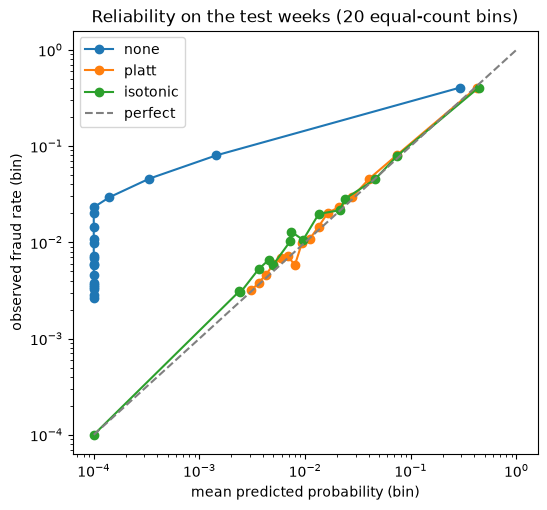

In [3]:
fig, ax = plt.subplots(figsize=(6, 5.5))
for name, p in p_t.items():
    t = reliability_table(y_t, p, n_bins=20)
    ax.plot(t["mean_p"].clip(1e-4), t["observed"].clip(1e-4), marker="o", label=name)
ax.plot([1e-4, 1], [1e-4, 1], color="gray", ls="--", label="perfect")
ax.set(xscale="log", yscale="log", xlabel="mean predicted probability (bin)", ylabel="observed fraud rate (bin)",
       title="Reliability on the test weeks (20 equal-count bins)")
ax.legend()
fig.savefig(FIG_DIR / "mr_reliability.png", dpi=120, bbox_inches="tight")

## Decision policies

The Bayes rule declines when p · C_FN > (1 − p) · C_FP, a per-transaction threshold p* = C_FP / (C_FP + C_FN). With the default costs:

In [4]:
for amt in [10, 50, 100, 500, 2000]:
    fn, fp = cost_fn(amt, costs), cost_fp(amt, costs)
    print(f"amount ${amt:>5}: C_FN = {fn:7.1f}, C_FP = {fp:6.2f}, decline if p > {fp / (fp + fn):.3f}")

amount $   10: C_FN =    25.0, C_FP =   5.30, decline if p > 0.175
amount $   50: C_FN =    65.0, C_FP =   6.50, decline if p > 0.091
amount $  100: C_FN =   115.0, C_FP =   8.00, decline if p > 0.065
amount $  500: C_FN =   515.0, C_FP =  20.00, decline if p > 0.037
amount $ 2000: C_FN =  2015.0, C_FP =  65.00, decline if p > 0.031


In [5]:
thr_f1 = best_f1_threshold(y_v, s_v)
thr_2pct = top_rate_threshold(s_v, 0.02)
print(f"F1-optimal threshold on valid: {thr_f1:.3f}; threshold declining 2% of valid: {thr_2pct:.3f}")

actions = {
    "D1 approve all": np.full(len(s_t), APPROVE),
    "D2 threshold 0.5": threshold_policy(s_t, 0.5),
    "D3 F1-optimal threshold": threshold_policy(s_t, thr_f1),
    "D4 decline top 2%": threshold_policy(s_t, thr_2pct),
    "D5 Bayes, raw score": bayes_policy(s_t, amount_t, costs),
    "D6 Bayes, Platt": bayes_policy(p_t["platt"], amount_t, costs),
    "D7 Bayes, isotonic": bayes_policy(p_t["isotonic"], amount_t, costs),
    "D8 3-action, isotonic": three_action_policy(p_t["isotonic"], amount_t, day_t, costs),
}
cost = {name: realized_cost(a, y_t, amount_t, costs) for name, a in actions.items()}

rows = []
for name, a in actions.items():
    vs_d1 = paired_cost_diff(cost[name], cost["D1 approve all"], groups_t, N_BOOT)  # saving = cost(D1) - cost(policy)
    vs_d2 = paired_cost_diff(cost["D2 threshold 0.5"], cost[name], groups_t, N_BOOT)
    rows.append({"policy": name, **policy_summary(a, y_t, amount_t, costs),
                 "saving_vs_approve_all": vs_d1.estimate, "saving_low": vs_d1.low, "saving_high": vs_d1.high,
                 "cost_vs_D2": vs_d2.estimate, "cost_vs_D2_low": vs_d2.low, "cost_vs_D2_high": vs_d2.high})
policies = pd.DataFrame(rows).set_index("policy")
policies.round(4)

F1-optimal threshold on valid: 0.072; threshold declining 2% of valid: 0.470


,total_cost,fraud_loss,declined_share,reviewed_share,good_customers_declined,fraud_usd_stopped,saving_vs_approve_all,saving_low,saving_high,cost_vs_D2,cost_vs_D2_low,cost_vs_D2_high
policy,,,,,,,,,,,,
D1 approve all,688583.0907,688583.0907,0.0000,0.000,0.0000,0.0000,0.0000,0.0000,0.0000,148690.9646,129798.7043,167917.7828
D2 threshold 0.5,539892.1261,537529.4697,0.0134,0.000,0.0025,0.2094,148690.9646,129798.7043,167917.7828,0.0000,0.0000,0.0000
D3 F1-optimal threshold,464143.6109,455122.1337,0.0220,0.000,0.0076,0.3305,224439.4798,195791.9924,256860.9127,-75748.5152,-98933.7189,-58007.3872
D4 decline top 2%,537764.4609,535290.8657,0.0138,0.000,0.0026,0.2123,150818.6298,131641.0618,169919.1414,-2127.6652,-3282.7516,-1141.0217
"D5 Bayes, raw score",445847.5436,435132.2147,0.0221,0.000,0.0078,0.3627,242735.5471,209887.3672,279209.0492,-94044.5825,-123890.9054,-71665.7083
"D6 Bayes, Platt",305345.4006,208692.8704,0.0809,0.000,0.0603,0.7009,383237.6900,328293.9424,443878.6818,-234546.7255,-290628.9626,-185328.7987
"D7 Bayes, isotonic",301792.3903,197196.6954,0.0878,0.000,0.0669,0.7177,386790.7003,330911.1487,446074.7394,-238099.7357,-294770.2596,-188805.9804
"D8 3-action, isotonic",208841.5446,150656.2009,0.0490,0.071,0.0302,0.7901,479741.5460,422661.6458,541645.4154,-331050.5815,-387037.8555,-278412.7882


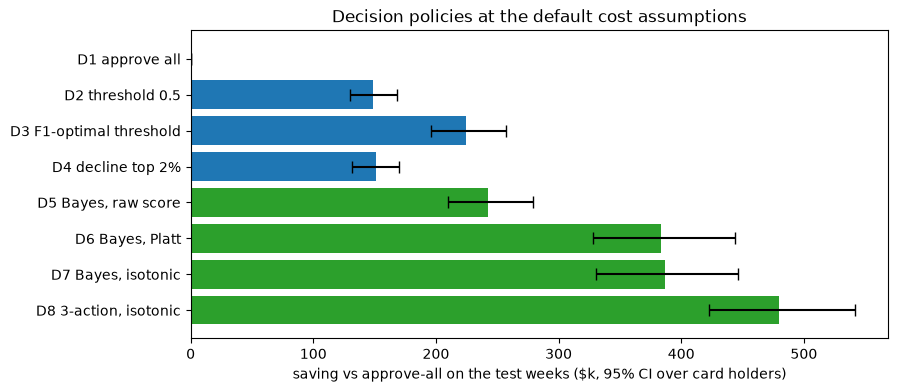

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
order = policies.index[::-1]
est = policies.loc[order, "saving_vs_approve_all"] / 1e3
err = np.vstack([est - policies.loc[order, "saving_low"] / 1e3, policies.loc[order, "saving_high"] / 1e3 - est])
ax.barh(range(len(order)), est, xerr=err, capsize=4, color=["C2" if "Bayes" in n or "3-action" in n else "C0" for n in order])
ax.set_yticks(range(len(order)), order)
ax.set(xlabel="saving vs approve-all on the test weeks ($k, 95% CI over card holders)", title="Decision policies at the default cost assumptions")
fig.savefig(FIG_DIR / "mr_policy_savings.png", dpi=120, bbox_inches="tight")

In [7]:
# Where is the money saved? Cost by product, default threshold vs the cost rule.
by_product = pd.DataFrame({
    name: pd.Series(cost[name]).groupby(test["ProductCD"].astype(str).to_numpy()).sum()
    for name in ["D1 approve all", "D2 threshold 0.5", "D7 Bayes, isotonic", "D8 3-action, isotonic"]
})
by_product.round(0)

,D1 approve all,D2 threshold 0.5,"D7 Bayes, isotonic","D8 3-action, isotonic"
C,110264.0,47013.0,25322.0,24218.0
H,31175.0,20821.0,10312.0,8115.0
R,71735.0,23578.0,9903.0,7582.0
S,10563.0,8005.0,5332.0,5066.0
W,464846.0,440475.0,250923.0,163861.0


## Sensitivity to the cost assumptions

For every cell of the grid in `costs.yaml`, the policies are re-run (the Bayes thresholds move with the costs; the score thresholds do not), and the cheapest policy is recorded.

In [8]:
grid = costs["sensitivity"]
compare = ["D2 threshold 0.5", "D3 F1-optimal threshold", "D4 decline top 2%", "D6 Bayes, Platt", "D7 Bayes, isotonic", "D8 3-action, isotonic"]
cells = []
for fp_fixed in grid["fp_fixed_grid"]:
    for margin in grid["margin_share_grid"]:
        c = load_costs(fp_fixed=fp_fixed, margin_share=margin)
        acts = {
            "D2 threshold 0.5": actions["D2 threshold 0.5"],
            "D3 F1-optimal threshold": actions["D3 F1-optimal threshold"],
            "D4 decline top 2%": actions["D4 decline top 2%"],
            "D6 Bayes, Platt": bayes_policy(p_t["platt"], amount_t, c),
            "D7 Bayes, isotonic": bayes_policy(p_t["isotonic"], amount_t, c),
            "D8 3-action, isotonic": three_action_policy(p_t["isotonic"], amount_t, day_t, c),
        }
        totals = {name: realized_cost(a, y_t, amount_t, c).sum() for name, a in acts.items()}
        best_threshold = min(totals[n] for n in compare[:3])
        cells.append({"fp_fixed": fp_fixed, "margin_share": margin, "best": min(totals, key=totals.get),
                      "D7_saving_vs_best_score_threshold": best_threshold - totals["D7 Bayes, isotonic"],
                      "D8_saving_vs_best_score_threshold": best_threshold - totals["D8 3-action, isotonic"]})
sens = pd.DataFrame(cells)
print(sens["best"].value_counts().to_string())
sens.pivot(index="fp_fixed", columns="margin_share", values="D7_saving_vs_best_score_threshold").round(0)

best
D8 3-action, isotonic    28
D6 Bayes, Platt           1
D7 Bayes, isotonic        1


margin_share,0.00,0.01,0.03,0.05,0.10
fp_fixed,,,,,
1,377737.0,290201.0,203141.0,156068.0,94918.0
2,344631.0,263774.0,190856.0,145714.0,90074.0
5,278467.0,221767.0,162351.0,129086.0,80889.0
10,219950.0,176151.0,129774.0,107371.0,66491.0
20,149459.0,123999.0,99378.0,79629.0,50943.0
50,86961.0,75442.0,60078.0,56152.0,41209.0


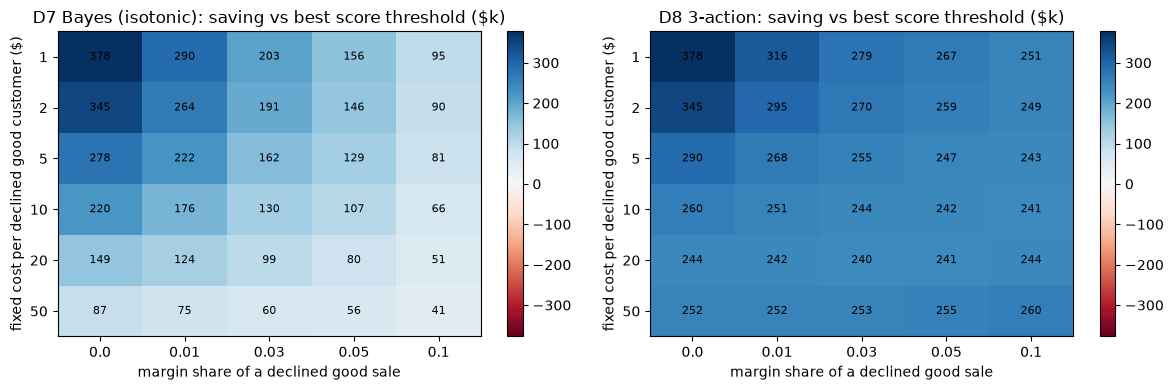

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in [(axes[0], "D7_saving_vs_best_score_threshold", "D7 Bayes (isotonic)"),
                       (axes[1], "D8_saving_vs_best_score_threshold", "D8 3-action")]:
    m = sens.pivot(index="fp_fixed", columns="margin_share", values=col) / 1e3
    lim = np.abs(m.to_numpy()).max()
    im = ax.imshow(m, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(m.shape[1]), m.columns)
    ax.set_yticks(range(m.shape[0]), m.index)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.annotate(f"{m.iat[i, j]:.0f}", (j, i), ha="center", va="center", fontsize=8)
    ax.set(xlabel="margin share of a declined good sale", ylabel="fixed cost per declined good customer ($)",
           title=f"{title}: saving vs best score threshold ($k)")
    fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "mr_cost_sensitivity.png", dpi=120, bbox_inches="tight")

In [10]:
out = pd.concat([
    valid.assign(p_platt=p_v["platt"], p_isotonic=p_v["isotonic"]),
    test.assign(p_platt=p_t["platt"], p_isotonic=p_t["isotonic"]),
], ignore_index=True)
out.to_parquet(PROCESSED_DIR / "scores_p2.parquet", index=False)
print(f"saved calibrated scores for {len(out):,} rows")

saved calibrated scores for 204,242 rows
